# 06 · Δχ² maps

A Δχ² map shows how well binary-lens models with separation *s* and mass ratio *q* fit the data: at every
(log s, log q) the other parameters are fitted. Maps reveal degenerate solutions and the range of allowed mass
ratios. `lenscape.lattice` computes a map in stages, so that fits do not stay in local minima:

1. **coarse seed grid** – quick fits on 2 × 2 merged cells give starting points;
2. **cell fits** – the best fit anywhere inside each cell (s, q free within it);
3. **lattice-point fits** – s, q fixed, started from the cell solutions nearby;
4. **neighbour refinement** – points are refitted from their neighbours' solutions until none improves;
5. **outlier recalculation** – points worse than their neighbours get a deep search.

`lenscape.refine` then splits the cells that a Δχ² band edge runs through.

> **Resolution vs. runtime.** Every lattice point costs a few fits (about 2 CPU-seconds each for this event).
> `gridres = 8` (64 points) runs in a few minutes; `gridres = 25` gives a fine map in about 10× the time;
> `levels = 2` in `refine` halves the cells twice along the band edges (about 4× the cost of `levels = 1`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures

In [2]:
data = lenscape.datasets.kmtnet("KMT-2022-BLG-0114", window=(9600, 9720))
p0 = np.array([9657.785, -0.02614, 34.51, np.log10(1.0033), np.log10(4.36e-3), 4.354, -3.0])
_, best = lenscape.fit_full(data, p0)
data = data.scale_errors(lenscape.error_factors(data, best))
chi2_best, best = lenscape.fit_full(data, best)
print(f"best fit chi2 = {chi2_best:.1f} for {len(data)} points")

best fit chi2 = 733.6 for 736 points


## The lattice

In [3]:
gridres = 8
logs = np.linspace(-0.008, 0.016, gridres)
logq = np.linspace(-2.60, -2.10, gridres)
result = lenscape.lattice(data, logs, logq, best=best)
print(f"{result['wall']:.0f} s; lowest chi2 {result['chi2_ref']:.1f}")

lattice 8 x 8 = 64 points; N = 736 (508 evaluated after binning the wings)

Stage 1/5: Coarse seed grid - quick fits on 2 x 2 merged cells, used as starting points


  seed grid: neighbour refinement, pass 1: 14 cells checked, 3 refitted, 3 improved by > 1.0 (max 85.1)


  seed grid: neighbour refinement, pass 2: 15 cells checked, 1 refitted, 1 improved by > 1.0 (max 12.6)


  seed grid: neighbour refinement, pass 3: 15 cells checked, 0 refitted, 0 improved by > 1.0
seed grid 4 x 4: 20 fits, 5s, min 718.16

Stage 2/5: Cell fits - best fit inside each cell


  neighbour refinement, pass 1: 54 cells checked, 9 refitted, 9 improved by > 1.0 (max 76.3)


...

recalculate outliers, pass 2: 9 outliers, 9 improved


recalculate outliers, pass 3: 6 outliers, 4 improved


recalculate outliers, pass 4: 4 outliers, 1 improved


recalculate outliers, pass 5: 4 outliers, 1 improved


recalculate outliers, pass 6: 4 outliers, 0 improved
done in 176s; lowest chi2 718.15
176 s; lowest chi2 718.2


`result["chi2"]` holds χ² at every lattice point, `result["pars"]` the best (t0, u0, tE, α, log ρ) there,
`result["chi2_ref"]` the lowest χ² found. Maps are shown either continuously or in the colour bands that papers
use (here Δχ² < 4, 16, 36, 64, 100, i.e. 2σ, 4σ, ... for one parameter).

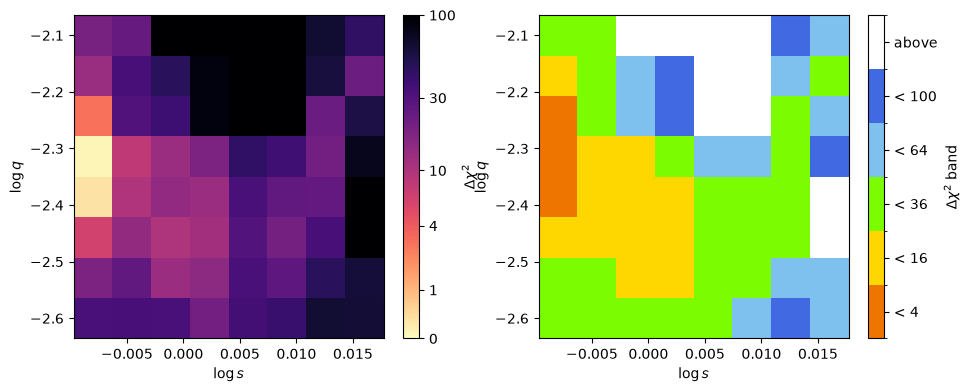

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
figures.plot_map(result, ax=ax[0])
figures.plot_map(result, bands=(4, 16, 36, 64, 100), ax=ax[1]);

## Why the stages matter

`result["chi2_first"]` keeps χ² before the neighbour refinement: fits started independently at each point often
stop in a local minimum.

In [5]:
improved = result["chi2_first"] - result["chi2"]
print(f"neighbour refinement and outlier search improved {np.sum(improved > 1)} of {improved.size} points "
      f"(largest gain {np.nanmax(improved):.0f} in chi2)")

neighbour refinement and outlier search improved 27 of 64 points (largest gain 190 in chi2)


## Finer cells along the contours

`refine` starts from the cells of stage 2 and splits those that a band edge runs through; each cell holds the
best fit anywhere inside it.

cells: 0 fits, 0s, best chi2 718.15
  -> 57 cells on band edges will be split (best fit still improving)

Stage 1/1: Finer cells, level 1 - 57 cells on band edges, each split into 4


  level 1: neighbour refinement, pass 1: 195 cells checked, 9 refitted, 9 improved by > 1.0 (max 58.8)


  level 1: neighbour refinement, pass 2: 194 cells checked, 2 refitted, 2 improved by > 1.0 (max 32.6)


  level 1: neighbour refinement, pass 3: 193 cells checked, 2 refitted, 2 improved by > 1.0 (max 60.6)


  level 1: neighbour refinement, pass 4: 194 cells checked, 4 refitted, 4 improved by > 1.0 (max 56.7)


  level 1: neighbour refinement, pass 5: 195 cells checked, 4 refitted, 4 improved by > 1.0 (max 87.1)


  level 1: neighbour refinement, pass 6: 195 cells checked, 3 refitted, 3 improved by > 1.0 (max 84.9)
level 1: 228 fits, 50s, best chi2 718.09 (8 cells inherited a better point)
235 cells, 252 new fits


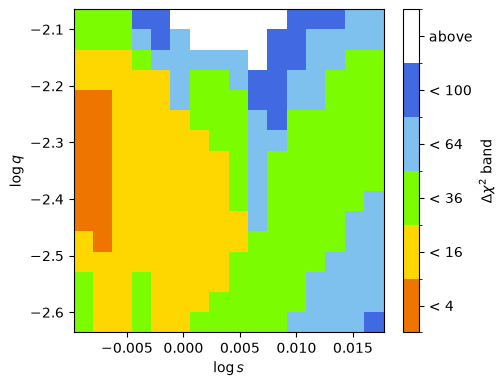

In [6]:
levels = 1
cells = lenscape.refine(result, data, levels=levels, best=best)
print(f"{len(cells['chi2'])} cells, {cells['nfit']} new fits")
figures.plot_map(cells, bands=(4, 16, 36, 64, 100));

## The trajectory angle

The fits also give the trajectory angle α at every point. Plotting α against log s shows how the solutions
connect: degenerate solutions often lie on continuous valleys.

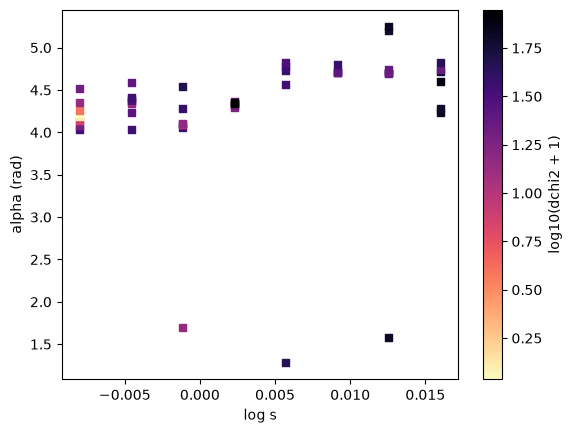

In [7]:
d = result["chi2"] - result["chi2_ref"]
alpha = np.mod(result["pars"][..., 3], 2 * np.pi)
LS = np.repeat(result["logs"][:, None], len(result["logq"]), 1)
ok = d < 100
plt.scatter(LS[ok], alpha[ok], c=np.log10(d[ok] + 1), cmap="magma_r", s=25, marker="s")
plt.colorbar(label="log10(dchi2 + 1)"); plt.xlabel("log s"); plt.ylabel("alpha (rad)");